# Validation: `hblteuk.jax.swsh` vs CPU reference

Visual companion to `tests/test_jax_swsh.py` (the authoritative pass/fail
gate — run `pytest tests/ -q`). Every section below **asserts** its check, so
executing this notebook end-to-end is itself a sanity test.

Reference data: the CPU ARPACK path (`hblteuk.swsh`) and the committed golden
file `tests/golden/golden_v1.npz` (see `dev/PHASE0.md`).

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt

from hblteuk.jax import spheroidal_eigs_batched, sphericalY_basis_matrix
from hblteuk.jax.swsh import coupling_matrices
from hblteuk.swsh import SpinWeightedSpheroidalHarmonic, spectral_sparse_matrix
import jax.numpy as jnp

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, fixed order
golden = np.load(pathlib.Path("..") / "tests" / "golden" / "golden_v1.npz")
print("golden file:", len(golden.files), "arrays")

golden file: 80 arrays


## 1. Coupling matrix: structure and symmetry

The batched dense matrix must reproduce the CPU sparse pentadiagonal matrix
exactly, and be symmetric (the property that lets us use `eigh`).

max |M - M.T| = 8.88e-16,  max |M_jax - M_cpu| = 8.88e-16


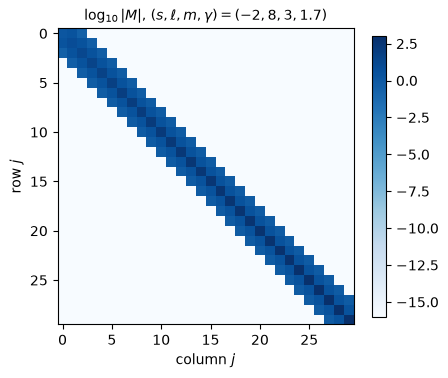

In [2]:
s, l, m, g = -2, 8, 3, 1.7
N = 30
M_jax = np.asarray(coupling_matrices(
    s, jnp.array([float(m)]), jnp.array([g]),
    jnp.array([float(max(abs(s), abs(m)))]), N)[0])
M_cpu = spectral_sparse_matrix(s, m, g, N).toarray()

asym = np.max(np.abs(M_jax - M_jax.T))
diff = np.max(np.abs(M_jax - M_cpu))
print(f"max |M - M.T| = {asym:.2e},  max |M_jax - M_cpu| = {diff:.2e}")
assert asym < 1e-12 and diff < 1e-12

fig, ax = plt.subplots(figsize=(4.6, 4))
with np.errstate(divide="ignore"):
    im = ax.imshow(np.log10(np.abs(M_jax) + 1e-300), cmap="Blues", vmin=-16, vmax=3)
ax.set_title(rf"$\log_{{10}}|M|$, $(s,\ell,m,\gamma)=({s},{l},{m},{g})$", fontsize=10)
ax.set_xlabel("column $j$"); ax.set_ylabel("row $j$")
fig.colorbar(im, shrink=0.85)
plt.tight_layout()

## 2. Spherical limit ($\gamma = 0$)

Eigenvalues must equal $\ell(\ell+1) - s(s+1)$ to machine precision and the
eigenvectors must be unit vectors.

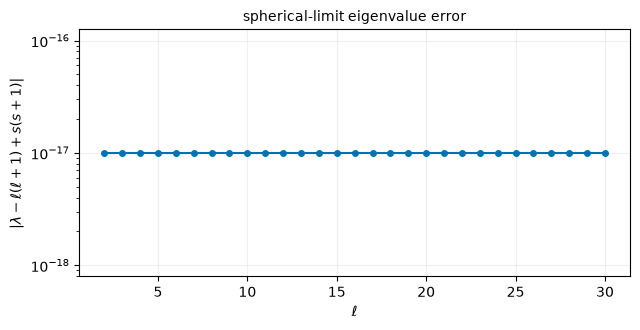

In [3]:
l = np.arange(2, 31)
lam, vec, lmin = spheroidal_eigs_batched(-2, l, np.full_like(l, 2), np.zeros(len(l)))
err = np.abs(np.asarray(lam) - (l * (l + 1) - 2))
assert np.max(err) < 1e-11

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.semilogy(l, err + 1e-17, "o-", color=C[0], lw=1.5, ms=4)
ax.set_xlabel(r"$\ell$"); ax.set_ylabel(r"$|\lambda - \ell(\ell+1) + s(s+1)|$")
ax.set_title("spherical-limit eigenvalue error", fontsize=10)
ax.grid(alpha=0.2)
plt.tight_layout()

## 3. Sweep vs CPU/ARPACK

Relative eigenvalue difference and max coefficient difference across an
$(\ell, m, \gamma)$ sweep. Tolerance lines mark the test-suite gates.

max rel eigenvalue diff: 1.84e-14
max coeff diff:          9.05e-15


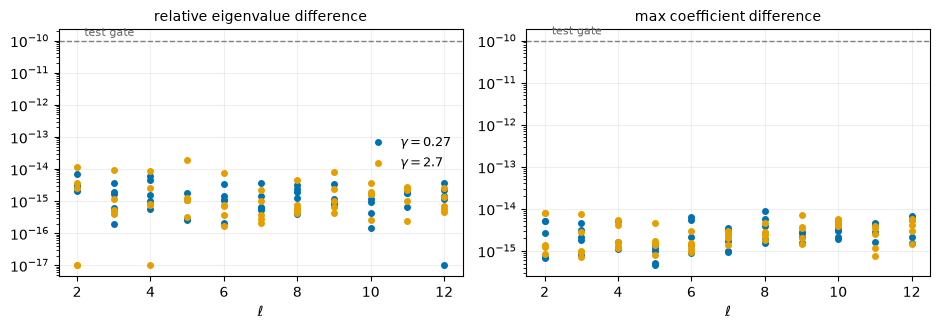

In [4]:
s = -2
cases = [(l, m, g) for l in range(2, 13) for m in (-l, -2, 0, 1, l)
         for g in (0.27, 2.7) if abs(m) <= l]
l_a = np.array([c[0] for c in cases]); m_a = np.array([c[1] for c in cases])
g_a = np.array([c[2] for c in cases])
lam, vec, lmin = spheroidal_eigs_batched(s, l_a, m_a, g_a)

lam_err, coeff_err = [], []
for b, (l, m, g) in enumerate(cases):
    S = SpinWeightedSpheroidalHarmonic(s, l, m, g)
    lam_err.append(abs((lam[b] - S.eigenvalue) / S.eigenvalue))
    cc = np.asarray(S.coeffs); vb = np.asarray(vec[b])
    n = min(len(cc), len(vb))
    coeff_err.append(np.max(np.abs(vb[:n] - cc[:n])))
lam_err = np.array(lam_err); coeff_err = np.array(coeff_err)
assert np.max(lam_err) < 1e-10 and np.max(coeff_err) < 1e-10

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharex=True)
for ax, err, name in [(axes[0], lam_err, "relative eigenvalue difference"),
                      (axes[1], coeff_err, "max coefficient difference")]:
    for gi, (gval, color) in enumerate(zip((0.27, 2.7), C)):
        sel = g_a == gval
        ax.semilogy(l_a[sel], err[sel] + 1e-17, "o", ms=4, color=color,
                    label=rf"$\gamma = {gval}$")
    ax.axhline(1e-10, ls="--", c="0.5", lw=1)
    ax.text(2.2, 1.4e-10, "test gate", fontsize=8, color="0.4")
    ax.set_xlabel(r"$\ell$"); ax.set_title(name, fontsize=10)
    ax.grid(alpha=0.2)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
print(f"max rel eigenvalue diff: {np.max(lam_err):.2e}")
print(f"max coeff diff:          {np.max(coeff_err):.2e}")

## 4. Golden-file regression

Same committed reference the pytest suite uses.

In [5]:
rows = []
for i in range(6):
    s_g, l_g, m_g, g_g = golden[f"swsh{i}_params"]
    lam, vec, _ = spheroidal_eigs_batched(int(s_g), [int(l_g)], [int(m_g)], [g_g])
    lam_ref = float(golden[f"swsh{i}_eigenvalue"])
    cc = golden[f"swsh{i}_coeffs"]; vb = np.asarray(vec[0])
    n = min(len(cc), len(vb))
    d_lam = abs((lam[0] - lam_ref) / lam_ref)
    d_c = np.max(np.abs(vb[:n] - cc[:n]))
    rows.append((int(s_g), int(l_g), int(m_g), g_g, d_lam, d_c))
    assert d_lam < 1e-10 and d_c < 1e-10

print(f"{'s':>3} {'l':>3} {'m':>3} {'gamma':>7} {'rel dlam':>10} {'max dc':>10}")
for r in rows:
    print(f"{r[0]:>3} {r[1]:>3} {r[2]:>3} {r[3]:>7.3f} {r[4]:>10.1e} {r[5]:>10.1e}")

  s   l   m   gamma   rel dlam     max dc
 -2   2   2   0.000    0.0e+00    0.0e+00
 -2   2   2   0.270    6.8e-15    2.7e-15
 -2   5  -3   1.350    1.1e-15    1.8e-15
 -2  10   7   2.700    7.7e-16    1.6e-15
  0   3   1   0.500    3.2e-16    1.0e-15
  2   2   2   0.270    1.1e-14    8.8e-16


## 5. Coefficient decay: why shared truncation is safe

The spherical-expansion coefficients decay exponentially away from
$j = \ell - \ell_{\min}$; the shared batch truncation (`nmax`) keeps every
mode's tail at round-off. Padding a mode to a bigger matrix only *improves*
its truncation (GPU plan §2.2, PHASE1.md design note 2).

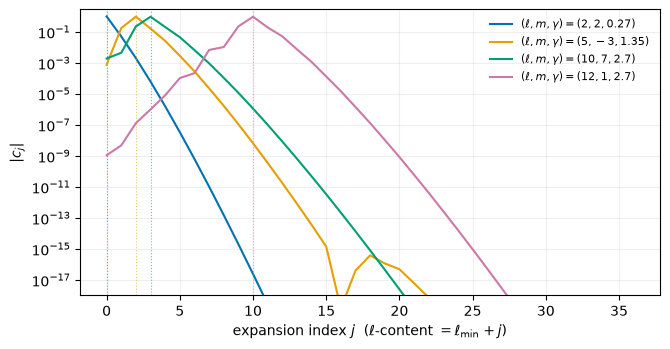

In [6]:
show = [(2, 2, 0.27), (5, -3, 1.35), (10, 7, 2.7), (12, 1, 2.7)]
lam, vec, lmin = spheroidal_eigs_batched(
    -2, [c[0] for c in show], [c[1] for c in show], [c[2] for c in show])

fig, ax = plt.subplots(figsize=(6.8, 3.6))
for color, (l, m, g), vb, lm in zip(C, show, np.asarray(vec), lmin):
    ax.semilogy(np.abs(vb) + 1e-300, lw=1.5, color=color,
                label=rf"$(\ell,m,\gamma)=({l},{m},{g})$")
    ax.axvline(l - lm, color=color, ls=":", lw=0.8, alpha=0.6)
ax.set_ylim(1e-18, 3)
ax.set_xlabel(r"expansion index $j$  ($\ell$-content $= \ell_{\min}+j$)")
ax.set_ylabel(r"$|c_j|$")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()

## 6. Harmonic reconstruction vs CPU evaluation

$S(\theta)$ from `coeffs @ basis` against the CPU class, with the residual
on a separate panel (same scale gate as the tests: $10^{-10}$).

max |S_jax - S_cpu| = 1.19e-15


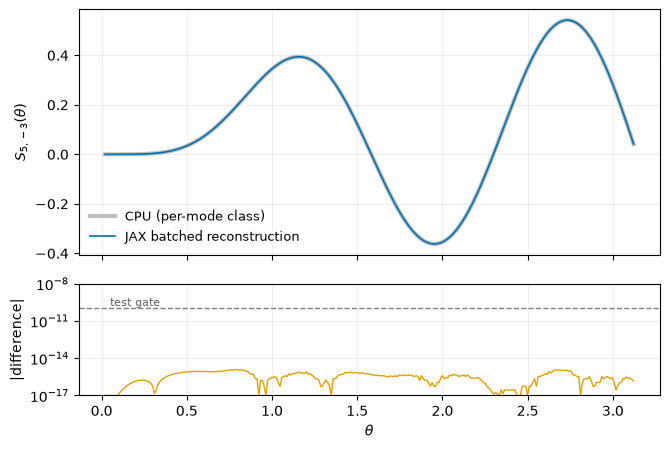

In [7]:
th = np.linspace(0.02, np.pi - 0.02, 300)
z = np.cos(th)
l, m, g = 5, -3, 1.35
b = show.index((l, m, g))
basis = sphericalY_basis_matrix(-2, m, int(lmin[b]), vec.shape[1], z)
S_jax = np.asarray(vec[b]) @ basis
S_cpu_obj = SpinWeightedSpheroidalHarmonic(-2, l, m, g)
S_cpu = np.array([S_cpu_obj.eval(t) for t in th])
resid = np.abs(S_jax - S_cpu)
assert np.max(resid) < 1e-10

fig, axes = plt.subplots(2, 1, figsize=(6.8, 4.6), sharex=True,
                         height_ratios=[2.2, 1])
axes[0].plot(th, S_cpu, lw=3, color="0.75", label="CPU (per-mode class)")
axes[0].plot(th, S_jax, lw=1.2, color=C[0], label="JAX batched reconstruction")
axes[0].set_ylabel(rf"$S_{{{l},{m}}}(\theta)$")
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(alpha=0.2)
axes[1].semilogy(th, np.maximum(resid, 1e-17), lw=1, color=C[1])
axes[1].axhline(1e-10, ls="--", c="0.5", lw=1)
axes[1].text(0.05, 1.6e-10, "test gate", fontsize=8, color="0.4")
axes[1].set_ylim(1e-17, 1e-8)
axes[1].set_xlabel(r"$\theta$"); axes[1].set_ylabel("|difference|")
axes[1].grid(alpha=0.2)
plt.tight_layout()
print(f"max |S_jax - S_cpu| = {np.max(resid):.2e}")

## Summary

All assertions above passed:

1. coupling matrix ≡ CPU sparse matrix, symmetric (→ `eigh` valid)
2. exact spherical limit
3. sweep vs ARPACK within test gates (1e-10)
4. golden-file regression within gates
5. exponential coefficient decay justifies shared truncation
6. harmonic reconstruction matches CPU evaluation

The pytest suite (`pytest tests/ -q`) remains the canonical gate; this
notebook is the visual audit trail.